# S-band Downlink Link Budget v3 (VCM, 550 km)

**What this notebook answers.** For the S-band DVB-S2 downlink (satellite → Durand roof dish), with the mission decisions that are now fixed:

1. **What is the link budget?** How much signal-to-noise reaches the ground at each elevation (Section 4).
2. **What does the VCM schedule look like?** Which MODCOD the satellite should use at each elevation, and how much data a pass delivers (Section 5).
3. **What is the impact of the remaining design choices?** Satellite pointing mode, satellite antenna and PA power (Section 6).
4. **How reliable is it, and which VCM buffer maximises delivered data?** Monte Carlo over the real uncertainties (Sections 7 and 8).

Section 9 summarises everything for the systems meeting.

**Decisions this notebook supports**

| ID | Decision | Where |
|---|---|---|
| D1 | Satellite pointing during passes: `steered` (GNC slews the antenna at the GS) or `nadir` (body-fixed, pointing down) | Section 6 |
| D2 | Satellite S-band antenna | Section 6 |
| D3 | Satellite PA output power | Section 6 |
| D4 | VCM buffer (how much predicted margin a MODCOD must have before the schedule uses it) | Section 8 |

**Simplifications** (state these next to any result you quote)
- Circular orbit, spherical Earth, **no Earth rotation** (a few % on pass length).
- "Average pass" assumes ground tracks offset uniformly across the visibility circle. Replace with TLE-propagated passes once the inclination is known.
- Constant 0.2 dB atmosphere (P.618 gives ~0.6 dB at 10°, < 0.2 dB above 30°, so this is ≤ 0.4 dB optimistic at the bottom of the pass).
- Constant GS antenna temperature, AWGN only, no Doppler or frequency-offset loss.
- Satellite pointing loss uses a parabolic main-lobe model, which is only accurate near boresight

## 1. Setup and constants
Imports, units and physical constants. Nothing here should need editing.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Units: multiply by these to get SI (e.g. 2.427*GHz is in Hz, 550*km is in m)
GHz, MHz, kHz, km = 1e9, 1e6, 1e3, 1e3

C   = 299_792_458.0       # speed of light [m/s]
MU  = 3.986004418e14      # Earth gravitational parameter [m^3/s^2]
R_EARTH_KM = 6371.0       # mean Earth radius [km], used everywhere
R_EARTH_M  = R_EARTH_KM*km
T0  = 290.0               # reference temperature for noise figures [K]
KT0_DBM_PER_HZ = -174.0   # k*T0 at 290 K [dBm/Hz]

f_Hz_S = 2.427*GHz        # S-band downlink carrier (satellite -> GS only)

RNG_SEED = 0              # one seed for every Monte Carlo, so reruns give identical numbers

# Chart colours: fixed categorical order (slot 1 is always the first series), plus a neutral grey
# for limits and reference lines. Colour follows the entity, never its rank.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
REF_GREY = "#8a8985"
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False})

## 2. Inputs
Every number the analysis uses lives here. To try a different scenario, edit a value here and re-run the notebook from the top.

In [3]:
# Labels: (FIXED | ASSUMED | TBC, who to ask)

# ---- DECISIONS: baseline choices for D1, D2, D3; every section uses these, Section 6 sweeps alternatives ----
DECISIONS = dict(
    pointing = "steered",                    # (TBC, Unknown) D1: "steered" or "nadir"
    ant      = "Taoglas patch (baseline)",   # (TBC, Unknown) D2: key into SAT_ANTENNAS
    pa_out_W = 2.0,                          # (TBC, Unknown) D3: satellite PA RF output [W]
)

# ---- SAT_S: satellite transmitter hardware (PA to antenna) and pointing ----
SAT_S = dict(
    loss_dB          = 0.5,   # (ASSUMED, Unknown) PA -> antenna loss: coax, connectors, filter
    ant_gain_dBi     = 5.0,   # (FIXED, Jason Jiang) Taoglas WPC.25A.07 patch, assumed linear polarisation
    pointing_err_deg = 5.0,   # (ASSUMED, River) pointing error, 95th percentile
)

# ---- SAT_ANTENNAS: antennas Section 6 compares; name -> (gain [dBi], 3 dB beamwidth [deg]) ----
# Beamwidth sets how fast pointing error costs gain.
SAT_ANTENNAS = {
    "Near-omni (turnstile)":    (2.0, 120.0),                  # (TBC, Unknown)
    "Taoglas patch (baseline)": (SAT_S["ant_gain_dBi"], 80.0), # (TBC, Unknown) beamwidth unconfirmed
    "Patch array 2x2":          (11.0, 40.0),                  # (TBC, Unknown)
    "Helical (7-turn)":         (13.0, 30.0),                  # (TBC, Unknown)
}

# ---- GS_S: ground-station receive chain, dish -> helix feed -> LNA at feed -> coax -> SDR ----
# Also holds the path losses between the two antennas (pol, pointing, atmosphere).
GS_S = dict(
    dish_gain_dBi = 31.4,   # (ASSUMED, Jason Jiang) 1.9 m mesh dish, ~55% efficiency
    feed_loss_dB  = 0.2,    # (ASSUMED, Unknown) feed -> LNA
    T_ant_K       = 100.0,  # (TBC, Unknown) sky + spillover + Wi-Fi; measure on the roof
    lna_nf_dB     = 0.8,    # (ASSUMED, Jason Jiang) SHF datasheet 0.8-1.2 dB
    lna_gain_dB   = 30.0,   # (TBC, Jason Jiang) SHF datasheet up to 26 dB
    post_loss_dB  = 1.0,    # (TBC, Unknown) LNA -> SDR coax
    rx_nf_dB      = 4.0,    # (ASSUMED, Jason Jiang) AntSDR E200 (AD9363)
    pol_loss_dB   = 3.0,    # (ASSUMED, Jason Jiang) linear sat patch -> circular helix feed
    point_loss_dB = 1.0,    # (ASSUMED, Unknown) dish tracking loss
    atm_loss_dB   = 0.2,    # (ASSUMED, Joel) ITU-R P.618: negligible below 10 GHz
)

# ---- WAVEFORM: how bits are sent (DVB-S2 settings, VCM table, packet format) ----
WAVEFORM = dict(
    Rs_sps         = 4e6,    # (ASSUMED, Joel) fixed symbol rate, ~4.8 MHz occupied
    include_8psk   = True,   # (TBC, Joel) False = QPSK-only VCM table
    impl_loss_dB   = 1.5,    # (TBC, Unknown) modem loss vs ideal DVB-S2 thresholds
    impl_extra_dB  = {"8PSK": 0.5},  # (TBC, Unknown) extra loss when using 8PSK: more sensitive to phase noise
    pilots         = True,   # (ASSUMED, Unknown)
    rolloff        = 0.20,   # (ASSUMED, Unknown) RRC roll-off, bandwidth printout only
    vcm_buffer_dB  = 3.0,    # (TBC, Joel) min predicted margin for a MODCOD; Section 8 recommends a value
    sched_step_deg = 1.0,    # (ASSUMED, Joel) VCM table: one MODCOD entry per degree of elevation
    payload_frac   = (1024 - 16)/1024,  # (ASSUMED, Joel) 1 KB packets, 16 B header
)

# ---- MISSION: orbit and passes ----
MISSION = dict(
    alt_km           = 550.0,   # (FIXED, Joel) systems meeting 12 Oct 2026
    min_el_deg       = 10.0,    # (ASSUMED, Joel) elevation mask; revisit after roof survey
    passes_per_day   = 4.0,     # (TBC, Unknown) replace with TLE pass count
)

# ---- CONSTRAINTS: limits shown as flags on results, not enforced ----
CONSTRAINTS = dict(
    pa_struct_W = 3.0,      # (TBC, River) structures limit
    pfd_binding = False,    # (TBC, Unknown) True on the 2200-2290 MHz experimental route
)

In [4]:
# Settings for the comparison and uncertainty studies (Sections 6-8), not the link itself.

# ---- CANDIDATES: alternatives Section 6 sweeps against DECISIONS ----
CANDIDATES = dict(
    pointing = ["steered", "nadir"],
    ant      = list(SAT_ANTENNAS),
    pa_W     = [1, 2, 3, 5, 7, 10],
)

# ---- MC: how far each input can stray from nominal, for the Monte Carlo (Section 7) ----
# Per-pass biases are drawn once per pass; per-second jitter at every time step.
MC = dict(
    n_passes          = 600,
    # per-pass biases [dB unless noted]
    sat_ant_std_dB    = 1.0,
    pa_std_dB         = 0.5,
    sat_loss_std_dB   = 0.3,
    dish_gain_std_dB  = 1.0,
    T_rfi_mean_K      = 40.0,   # extra T_ant from Wi-Fi [K], exponential (only adds)
    lna_nf_std_dB     = 0.2,
    pol_std_dB        = 0.5,    # around GS_S["pol_loss_dB"]
    impl_std_dB       = 0.5,    # around WAVEFORM["impl_loss_dB"]
    # per-second jitter
    dish_point_std_dB = 0.5,    # around GS_S["point_loss_dB"], clipped at 0
    # sat pointing error: Rayleigh with SAT_S["pointing_err_deg"] as its 95th percentile
)

# ---- BUFFER_SWEEP: VCM buffers Section 8 tries, and the reliability floor ----
BUFFER_SWEEP = dict(
    buffers_dB       = np.arange(0.0, 8.01, 0.5),
    worst_step_floor = 0.80,    # (TBC, Joel) reject buffers where any step decodes on < 80% of passes
)

# ---- Simulation settings (resolution only, not physics) ----
N_TRACKS = 40     # ground tracks averaged into the "average pass" (Sections 5-6)
DT_S     = 1.0    # time step through a pass [s]; the VCM table is looked up every step

## 3. Core functions
Three sections: General, Geometry, and PFD (power flux density at the ground vs the ITU Article 21 limit).
The link budget functions are in Section 4 and the MODCOD table and VCM functions in Section 5, where they are first used.

In [5]:
# ===================== 3.1 General =====================
# SOURCE CHECK (vs trade study v1 / Link Budget v2; compared numerically, identical outputs):
#   db, lin, fspl_db, therm_noise_dbm, nf_to_te, tsys_at_lna_input, slant_range_km -> SAME as source
#   Not carried over: prx_dBm (replaced by link_budget in 3.3), loss_sample (the Monte Carlo clips inline)

def db(x):  return 10*np.log10(x)                          # linear ratio -> dB
def lin(x): return 10**(np.asarray(x, dtype=float)/10)     # dB -> linear ratio

def fspl_db(d_m, f_hz):
    '''Free-space path loss [dB] over distance d_m at frequency f_hz: 20 log10(4 pi d f / c).'''
    return 20*np.log10(4*np.pi*d_m*f_hz/C)

def therm_noise_dbm(T_sys_K, B_Hz):
    '''Thermal noise power kTB [dBm]. With B_Hz = 1 this is the noise density N0 [dBm/Hz].'''
    return KT0_DBM_PER_HZ + 10*np.log10(T_sys_K/T0) + 10*np.log10(B_Hz)

def nf_to_te(nf_dB):
    '''Noise figure [dB] -> equivalent noise temperature [K]: T0 (10^(NF/10) - 1).'''
    return T0*(lin(nf_dB) - 1)

def tsys_at_lna_input(T_ant_K, pre_loss_dB, lna_nf_dB, lna_gain_dB, post_loss_dB, rx_nf_dB):
    '''System noise temperature [K] referred to the LNA input.
    Chain: antenna -> passive loss (pre_loss) -> LNA -> passive loss (post_loss) -> receiver.
    The pre-LNA loss both attenuates the antenna noise and adds its own; everything after the
    LNA is divided by the LNA gain, which is why a good LNA at the feed matters so much.'''
    L_pre   = lin(pre_loss_dB)
    T_in    = T_ant_K/L_pre + T0*(1 - 1/L_pre)
    L_post  = lin(post_loss_dB)
    Te_post = T0*(L_post - 1) + L_post*nf_to_te(rx_nf_dB)
    return T_in + nf_to_te(lna_nf_dB) + Te_post/lin(lna_gain_dB)

def slant_range_km(alt_km, elev_deg):
    '''GS-to-satellite distance [km] for a satellite at alt_km seen at elev_deg.'''
    e = np.radians(elev_deg)
    r = R_EARTH_KM
    return np.sqrt((r + alt_km)**2 - (r*np.cos(e))**2) - r*np.sin(e)

TSYS_K = tsys_at_lna_input(GS_S["T_ant_K"], GS_S["feed_loss_dB"], GS_S["lna_nf_dB"],
                           GS_S["lna_gain_dB"], GS_S["post_loss_dB"], GS_S["rx_nf_dB"])   # GS system temperature [K]
print(f"GS system temperature at the LNA input: {TSYS_K:.0f} K")

GS system temperature at the LNA input: 168 K


In [6]:
# ===================== 3.2 Geometry (circular orbit, Earth rotation ignored) =====================
# Units: central_angle / elevation_from_central_angle work in RADIANS and METRES; the rest in km and degrees.
# SOURCE CHECK (vs trade study v1; compared numerically):
#   central_angle, elevation_from_central_angle, nadir_angle_deg -> SAME as source
#   pass_profile -> CHANGED: a pass whose peak is at or below the mask returns T = 0 and no samples (the source
#                   forced a 0.001 deg-above-mask pass of ~4 s). Identical output for every pass above the mask.
#   max_elevs         -> NEW: peak elevations of n passes with ground tracks spread across the visible circle:
#                        evenly spaced for the "average pass" (Sections 5-6), random for the Monte Carlo (Section 7).

def central_angle(el_rad, h_m):
    '''Earth-centre angle [rad] between the GS and the sub-satellite point when the
    satellite is at elevation el_rad: lambda = arccos(R/(R+h) cos(el)) - el.'''
    return np.arccos(R_EARTH_M/(R_EARTH_M + h_m)*np.cos(el_rad)) - el_rad

def elevation_from_central_angle(lam, h_m):
    '''Inverse of central_angle: elevation [rad] for Earth-centre angle lam [rad].'''
    return np.arctan2(np.cos(lam) - R_EARTH_M/(R_EARTH_M + h_m), np.sin(lam))

def nadir_angle_deg(alt_km, elev_deg):
    '''How far off "straight down" [deg] the satellite sees a GS at elev_deg.
    0 deg overhead; ~65 deg for a GS at 10 deg elevation from 550 km.'''
    e = np.radians(elev_deg)
    return np.degrees(np.arcsin(R_EARTH_KM/(R_EARTH_KM + alt_km)*np.cos(e)))

def pass_profile(alt_km, min_el_deg, max_el_deg, dt=1.0):
    '''Elevation vs time for one pass that peaks at max_el_deg, above the mask min_el_deg.
    Spherical right triangle: cos(lambda(t)) = cos(lambda_min) cos(omega t), where lambda_min is the
    closest approach, omega the orbital rate and t the time from closest approach.
    Returns dict(t [s from AOS], T [s], el_deg). Uses np.arange, so the last sample can land up to
    one step past the mask; integrating with rate.sum()*dt over-counts by < 1 s per pass (< 0.3%).
    A pass that never rises above the mask returns T = 0 and no samples.'''
    if max_el_deg <= min_el_deg:
        return dict(t=np.array([]), T=0.0, el_deg=np.array([]))
    h = alt_km*km
    lam_min  = central_angle(np.radians(max_el_deg), h)     # closest approach
    lam_mask = central_angle(np.radians(min_el_deg), h)     # where the satellite crosses the mask
    omega = np.sqrt(MU/(R_EARTH_M + h)**3)                  # orbital rate [rad/s]
    Dmax = np.arccos(np.clip(np.cos(lam_mask)/np.cos(lam_min), -1, 1))   # along-track half-angle of the pass
    T = 2*Dmax/omega
    t = np.arange(-T/2, T/2 + dt/2, dt)
    D = np.clip(omega*t, -Dmax, Dmax)
    lam = np.arccos(np.clip(np.cos(lam_min)*np.cos(D), -1, 1))
    return dict(t=t - t[0], T=T, el_deg=np.degrees(elevation_from_central_angle(lam, h)))

def max_elevs(alt_km, min_el_deg, n, rng=None):
    '''Peak elevations [deg] of n passes with ground tracks offset from overhead out to the edge of visibility.
    rng=None: offsets evenly spaced, so averaging gives the "average pass" (most passes are low).
    rng given: random offsets, one per simulated Monte Carlo pass.'''
    h = alt_km*km
    lam_mask = central_angle(np.radians(min_el_deg), h)
    frac = (np.arange(n) + 0.5)/n if rng is None else rng.uniform(0, 1, n)
    return np.degrees(elevation_from_central_angle(frac*lam_mask, h))

# Quick sanity check: pass durations at the mission altitude and mask
for me in (15, 30, 60, 90):
    p = pass_profile(MISSION["alt_km"], MISSION["min_el_deg"], me)
    print(f"{MISSION['alt_km']:g} km, {MISSION['min_el_deg']:g} deg mask, peak {me:>2} deg: "
          f"pass lasts {p['T']/60:4.1f} min")

550 km, 10 deg mask, peak 15 deg: pass lasts  4.6 min
550 km, 10 deg mask, peak 30 deg: pass lasts  7.0 min
550 km, 10 deg mask, peak 60 deg: pass lasts  7.8 min
550 km, 10 deg mask, peak 90 deg: pass lasts  7.9 min


In [7]:
# ===================== 3.3 PFD (ITU RR Article 21, Table 21-4) =====================
# Uses link_budget (Section 4) for the EIRP toward the GS; only called from Section 5 on.
# Limit row for 2025-2110 / 2200-2300 MHz. Table 21-4 has NO row at 2.4 GHz: binding on the experimental
# (2200-2290 MHz) route, a coordination benchmark on the amateur route. See CONSTRAINTS["pfd_binding"].
# SOURCE CHECK: not in trade study v1. Vs the PFD check in the earlier link budget notebook (mission_control):
#   pfd_limit_dBW_m2_4kHz -> SAME
#   pfd_dBW_m2_4kHz       -> CHANGED: EIRP toward the GS now includes the satellite pointing loss (0.05 dB for the
#                            steered patch at 5 deg; large for nadir pointing at low elevation). 4 kHz / Rs scaling SAME.
#   pfd_worst_excess_dB, pfd_max_power_W -> SAME logic (now take a design dict)

def pfd_limit_dBW_m2_4kHz(elev_deg):
    '''Table 21-4 limit [dB(W/m^2) in 4 kHz] vs angle of arrival (= elevation).'''
    e = np.asarray(elev_deg, dtype=float)
    return np.where(e <= 5, -154.0, np.where(e < 25, -154.0 + 0.5*(e - 5), -144.0))

def pfd_dBW_m2_4kHz(elev_deg, design=None, alt_km=None, Rs=None):
    '''Peak PFD at the GS in any 4 kHz [dB(W/m^2)], free space (no atmosphere, by definition of the limit).
    EIRP toward the GS includes the satellite pointing loss. The RRC spectrum is flat at P/Rs, so the
    peak 4 kHz density uses Rs, not the occupied bandwidth: a LOWER symbol rate means a HIGHER PFD.'''
    Rs = WAVEFORM["Rs_sps"] if Rs is None else Rs
    b = link_budget(elev_deg, design=design, alt_km=alt_km, Rs=Rs)
    eirp_dBW = b["= EIRP toward GS (dBm)"] - 30
    d_m = b["Slant range (km)"]*km
    return eirp_dBW - 10*np.log10(4*np.pi*d_m**2) + 10*np.log10(4e3/Rs)

def pfd_worst_excess_dB(design=None, alt_km=None, Rs=None):
    '''Largest (PFD - limit) over 0-90 deg [dB] along the GS line of sight. > 0 = over the limit.
    (A full assessment would scan the whole footprint, not just the GS direction.)'''
    e = np.linspace(0, 90, 181)
    return float(np.max(pfd_dBW_m2_4kHz(e, design, alt_km, Rs) - pfd_limit_dBW_m2_4kHz(e)))

def pfd_max_power_W(design=None, alt_km=None, Rs=None):
    '''Largest PA output [W] that keeps the PFD under the limit (PFD rises 1 dB per dB of PA power).'''
    d = {**DECISIONS, **(design or {})}
    return d["pa_out_W"]*10**(-pfd_worst_excess_dB(d, alt_km, Rs)/10)

## 4. Link budget (the supply)
The classic line-item budget for the baseline `DECISIONS` at the mission altitude. It ends at the **available $E_s/N_0$** at the fixed symbol rate:

$$
\frac{E_s}{N_0}\Big|_{\rm avail} = \underbrace{\mathrm{EIRP} - L_{\rm path} - L_{\rm atm} - L_{\rm pol} - L_{\rm pt,GS} + G_{\rm dish} - L_{\rm feed}}_{P_{rx}} \;-\; N_0 \;-\; 10\log_{10} R_s
$$

There is no margin yet, because margin only exists once a MODCOD is chosen. That is the VCM decision in Section 5.

In [8]:
# ===================== Link budget functions =====================
# SOURCE CHECK (vs trade study v1; compared numerically):
#   sat_point_loss_db -> CHANGED: the "none" pointing mode is removed. Identical for "steered" and "nadir".
#   link_budget       -> NEW: replaces source build_s_spec + prx_S + prx_dBm, which between them returned only
#                        the received power. Now one function returns every line of the budget (the Section 4
#                        table), so each loss can be seen and checked. Received power and system temperature are
#                        identical to source prx_S; available Es/N0 minus (threshold + impl. loss) is identical
#                        to source margin_S_dB.

POINT_LOSS_CAP_DB = 25.0   # the parabolic model is meaningless far off boresight; cap the loss here

def sat_point_loss_db(alt_km, elev_deg, ant, err_deg, pointing):
    '''Satellite antenna pointing loss [dB], parabolic main-lobe model 12 (theta / beamwidth)^2, capped.
    theta = err_deg for "steered" (GNC points the antenna at the GS, only the error remains), or
    nadir angle + err_deg for "nadir" (antenna fixed pointing down). err_deg may be an array.'''
    bw3 = SAT_ANTENNAS[ant][1]
    elev = np.asarray(elev_deg, dtype=float)
    if pointing == "steered":
        theta = np.zeros_like(elev) + err_deg
    elif pointing == "nadir":
        theta = nadir_angle_deg(alt_km, elev) + err_deg
    else:
        raise ValueError(f"Invalid pointing model: {pointing}")
    return np.minimum(12*(theta/bw3)**2, POINT_LOSS_CAP_DB)

def link_budget(elev_deg, design=None, alt_km=None, err_deg=None, Rs=None):
    '''S-band link budget at elevation(s) elev_deg, one line per gain or loss.
    Starts at the satellite PA output, adds every gain and subtracts every loss on the way to the GS
    receiver (= received power), then compares that with the receiver noise to get the available Es/N0:
    the signal-to-noise per symbol the link delivers at the fixed symbol rate.
    Returns a dict, one entry per budget line (the Section 4 table), each an array over elev_deg [dB unless noted].
    design overrides DECISIONS, e.g. dict(ant="Helical (7-turn)", pa_out_W=3); alt_km, err_deg and Rs
    override MISSION, SAT_S and WAVEFORM. No margin here: margin depends on which MODCOD is used, and
    vcm_select chooses that afterwards.'''
    d   = {**DECISIONS, **(design or {})}
    alt = MISSION["alt_km"] if alt_km is None else alt_km
    err = SAT_S["pointing_err_deg"] if err_deg is None else err_deg
    Rs  = WAVEFORM["Rs_sps"] if Rs is None else Rs
    el  = np.asarray(elev_deg, dtype=float)
    gain_dBi, _ = SAT_ANTENNAS[d["ant"]]

    b = {}
    b["PA output (dBm)"]           = np.full_like(el, 10*np.log10(d["pa_out_W"]*1e3))
    b["- Sat PA->antenna loss"]    = np.full_like(el, SAT_S["loss_dB"])
    b["+ Sat antenna gain (dBi)"]  = np.full_like(el, gain_dBi)
    b["- Sat pointing loss"]       = sat_point_loss_db(alt, el, d["ant"], err, d["pointing"])
    b["= EIRP toward GS (dBm)"]    = (b["PA output (dBm)"] - b["- Sat PA->antenna loss"]
                                      + b["+ Sat antenna gain (dBi)"] - b["- Sat pointing loss"])
    b["Slant range (km)"]          = slant_range_km(alt, el)
    b["- Free-space path loss"]    = fspl_db(b["Slant range (km)"]*km, f_Hz_S)
    b["- Atmospheric loss"]        = np.full_like(el, GS_S["atm_loss_dB"])
    b["- Polarization loss"]       = np.full_like(el, GS_S["pol_loss_dB"])
    b["- GS pointing loss"]        = np.full_like(el, GS_S["point_loss_dB"])
    b["+ Dish gain (dBi)"]         = np.full_like(el, GS_S["dish_gain_dBi"])
    b["- Feed loss"]               = np.full_like(el, GS_S["feed_loss_dB"])
    b["= Received power (dBm)"]    = (b["= EIRP toward GS (dBm)"] - b["- Free-space path loss"]
                                      - b["- Atmospheric loss"] - b["- Polarization loss"] - b["- GS pointing loss"]
                                      + b["+ Dish gain (dBi)"] - b["- Feed loss"])
    b["System temperature (K)"]    = np.full_like(el, TSYS_K)
    b["G/T (dB/K)"]                = GS_S["dish_gain_dBi"] - GS_S["feed_loss_dB"] - 10*np.log10(b["System temperature (K)"])
    b["N0 (dBm/Hz)"]               = therm_noise_dbm(b["System temperature (K)"], 1.0)
    b["= C/N0 (dB-Hz)"]            = b["= Received power (dBm)"] - b["N0 (dBm/Hz)"]
    b["- 10 log10(Rs)"]            = np.full_like(el, 10*np.log10(Rs))
    b["= Available Es/N0"]         = b["= C/N0 (dB-Hz)"] - b["- 10 log10(Rs)"]
    return b

In [9]:
BUDGET_ELEVS = [10, 20, 30, 45, 60, 90]

b = link_budget(BUDGET_ELEVS)
budget = pd.DataFrame({f"{e} deg": [b[k][i] for k in b] for i, e in enumerate(BUDGET_ELEVS)}, index=list(b))
print(f"S-band downlink budget: {MISSION['alt_km']:g} km, {DECISIONS['ant']}, {DECISIONS['pa_out_W']:g} W, "
      f"{DECISIONS['pointing']} with {SAT_S['pointing_err_deg']:g} deg error, {WAVEFORM['Rs_sps']/1e6:g} Msym/s")
display(budget.round(2))

S-band downlink budget: 550 km, Taoglas patch (baseline), 2 W, steered with 5 deg error, 4 Msym/s


,10 deg,20 deg,30 deg,45 deg,60 deg,90 deg
PA output (dBm),33.01,33.01,33.01,33.01,33.01,33.01
- Sat PA->antenna loss,0.50,0.50,0.50,0.50,0.50,0.50
+ Sat antenna gain (dBi),5.00,5.00,5.00,5.00,5.00,5.00
- Sat pointing loss,0.05,0.05,0.05,0.05,0.05,0.05
= EIRP toward GS (dBm),37.46,37.46,37.46,37.46,37.46,37.46
Slant range (km),1815.08,1293.55,992.78,749.11,626.89,550.00
- Free-space path loss,165.33,162.38,160.09,157.64,156.09,154.96
- Atmospheric loss,0.20,0.20,0.20,0.20,0.20,0.20
- Polarization loss,3.00,3.00,3.00,3.00,3.00,3.00
- GS pointing loss,1.00,1.00,1.00,1.00,1.00,1.00


## 5. VCM schedule and data per pass
The satellite carries a table: for each elevation step, the fastest allowed MODCOD (QPSK, plus 8PSK if enabled) whose **predicted** margin is at least `WAVEFORM["vcm_buffer_dB"]`. Below the elevation where even QPSK 1/4 lacks the buffer, the transmitter stays off. The symbol rate never changes.

Outputs:
1. The MODCOD table: each MODCOD's required $E_s/N_0$ (ideal threshold + implementation loss) and info rate.
2. Chart: the Section 4 available $E_s/N_0$ curve against each MODCOD's requirement. VCM picks the highest requirement line that sits at least one buffer below the curve.
3. The schedule: the elevation at which each MODCOD starts, with its rate and predicted margin.
4. Info rate over three example passes.
5. Data per pass (overhead, 45° peak, average over all passes) and per day, **assuming every frame decodes**. Section 7 removes that assumption.
6. PFD check of this design.

Modulations: QPSK, 8PSK; symbol rate 4 Msym/s, occupied bandwidth ~4.8 MHz


,req_esn0_dB,impl_dB,req_total_dB,rate_Mbps
modcod,,,,
QPSK 1/4,-2.35,1.5,-0.85,1.91
QPSK 1/3,-1.24,1.5,0.26,2.56
QPSK 2/5,-0.30,1.5,1.20,3.08
QPSK 1/2,1.00,1.5,2.50,3.86
QPSK 3/5,2.23,1.5,3.73,4.64
QPSK 2/3,3.10,1.5,4.60,5.16
QPSK 3/4,4.03,1.5,5.53,5.81
QPSK 4/5,4.68,1.5,6.18,6.20
QPSK 5/6,5.18,1.5,6.68,6.46


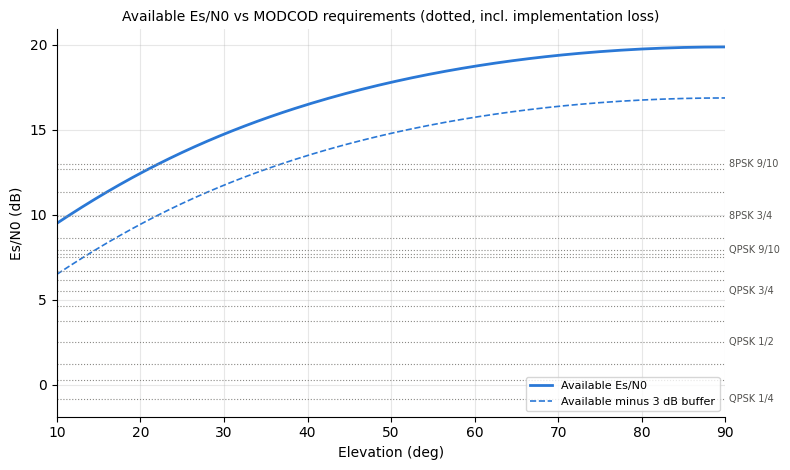

In [ ]:
# ===================== MODCOD table and VCM functions =====================
# SOURCE CHECK (vs trade study v1; compared numerically):
#   DVBS2_TABLE_ALL   -> CHANGED: QPSK + 8PSK rows only. GMSK, LoRa and APSK modes dropped.
#   pilot_factor      -> SAME as source
#   MODCODS           -> NEW: one table, one row per MODCOD sorted slowest to fastest: ideal Es/N0 threshold,
#                        implementation loss (8PSK adds WAVEFORM["impl_extra_dB"]), req_total_dB = the two added
#                        (what the link must actually deliver), and info rate at the fixed symbol rate after pilots.
#                        Row 0 is "off" (rate 0, never decodes), so a MODCOD index of 0 means the transmitter is off.
#   vcm_select        -> NEW: fixed symbol rate, fastest MODCOD with >= buffer predicted margin. For QPSK only it
#                        matches the source "best QPSK at fixed Rs" rule exactly. The source solve_mode /
#                        best_rate_bps (which vary the symbol rate) are deliberately not used.
#   vcm_schedule      -> NEW: builds the VCM table the satellite carries: one MODCOD per elevation step, chosen
#                        from the nominal budget before the pass.
#   modcod_at_elevation   -> NEW: during a pass, finds the table row for the current elevation (the row at or below it).
#   deterministic_pass_MB -> NEW: MB from one pass with a given peak elevation flown with a given schedule,
#                        assuming every frame decodes.
#   average_pass_MB   -> NEW: builds the schedule once, then averages deterministic_pass_MB over N_TRACKS ground
#                        tracks (the "average pass").

# ---- DVB-S2 MODCODs: ETSI EN 302 307-1 Table 13 (ideal Es/N0 at quasi-error-free, normal frames) ----
# name: (required Es/N0 [dB], spectral efficiency eta [info bits per symbol, no pilots], bits per symbol m)
DVBS2_TABLE_ALL = {
    "QPSK 1/4": (-2.35, 0.490, 2), "QPSK 1/3": (-1.24, 0.656, 2), "QPSK 2/5": (-0.30, 0.789, 2),
    "QPSK 1/2": ( 1.00, 0.988, 2), "QPSK 3/5": ( 2.23, 1.188, 2), "QPSK 2/3": ( 3.10, 1.322, 2),
    "QPSK 3/4": ( 4.03, 1.487, 2), "QPSK 4/5": ( 4.68, 1.587, 2), "QPSK 5/6": ( 5.18, 1.655, 2),
    "QPSK 8/9": ( 6.20, 1.766, 2), "QPSK 9/10": (6.42, 1.789, 2),
    "8PSK 3/5": ( 5.50, 1.779, 3), "8PSK 2/3": ( 6.62, 1.981, 3), "8PSK 3/4": ( 7.91, 2.228, 3),
    "8PSK 5/6": ( 9.35, 2.479, 3), "8PSK 8/9": (10.69, 2.646, 3), "8PSK 9/10": (10.98, 2.679, 3),
}
MODULATIONS = ("QPSK", "8PSK") if WAVEFORM["include_8psk"] else ("QPSK",)
DVBS2_TABLE = {k: v for k, v in DVBS2_TABLE_ALL.items() if k.split()[0] in MODULATIONS}

def pilot_factor(m, normal=True):
    '''Fraction of transmitted symbols carrying data with pilots on: 90-symbol header, 90-symbol slots,
    36 pilot symbols every 16 slots. m = bits per symbol: QPSK (2) -> 0.9762, 8PSK (3) -> 0.9765.'''
    slots = (64800 if normal else 16200)/m/90
    nopilot = 90*(1 + slots)
    return nopilot/(nopilot + 36*np.floor((slots - 1)/16))

# One row per MODCOD, slowest -> fastest. Row 0 is "off": rate 0 and no threshold (NaN), so it never "fits" or
# decodes, and index 0 means the transmitter is off.
MODCODS = pd.DataFrame([dict(modcod=n, req_esn0_dB=req,
                             impl_dB=WAVEFORM["impl_loss_dB"] + WAVEFORM["impl_extra_dB"].get(n.split()[0], 0.0),
                             rate_bps=WAVEFORM["Rs_sps"]*eta*(pilot_factor(m) if WAVEFORM["pilots"] else 1.0))
                        for n, (req, eta, m) in DVBS2_TABLE.items()]).sort_values("rate_bps")
MODCODS = pd.concat([pd.DataFrame([dict(modcod="off", req_esn0_dB=np.nan, impl_dB=np.nan, rate_bps=0.0)]), MODCODS],
                    ignore_index=True)
MODCODS["req_total_dB"] = MODCODS["req_esn0_dB"] + MODCODS["impl_dB"]   # what the link must actually supply
REQ_TOTAL_DB = MODCODS["req_total_dB"].to_numpy()                       # numpy copies for fast indexing
RATE_BPS     = MODCODS["rate_bps"].to_numpy()

def vcm_select(esn0_avail_dB, buffer_dB):
    '''VCM rule: row of the FASTEST MODCOD whose predicted margin (available Es/N0 - req_total_dB) is at
    least buffer_dB; 0 ("off") if none fits.'''
    ok = (np.asarray(esn0_avail_dB)[..., None] - REQ_TOTAL_DB) >= buffer_dB   # available MODCOD selection, excluding the "off" MODCOD
    return np.where(ok, RATE_BPS, -1.0).argmax(axis=-1)                       # choosing maximum data rate MODCOD, or "off" if no MODCOD availables

def vcm_schedule(buffer_dB, design=None, alt_km=None):
    '''The VCM table the satellite would carry: one MODCOD per elevation step from the mask to 90 deg.
    Built from the NOMINAL link budget (it is decided before the pass). Returns (grid, sched_modcod): elevations [deg] and the MODCOD row chosen for each.'''
    grid = np.arange(MISSION["min_el_deg"], 90 + 1e-9, WAVEFORM["sched_step_deg"])
    esn0 = link_budget(grid, design=design, alt_km=alt_km)["= Available Es/N0"]
    return grid, vcm_select(esn0, buffer_dB)

def modcod_at_elevation(grid, sched_modcod, el_deg):
    '''MODCOD index in use at elevation(s) el_deg.'''
    k = np.clip(np.floor((np.asarray(el_deg) - grid[0])/WAVEFORM["sched_step_deg"]).astype(int), 0, len(grid) - 1)
    return sched_modcod[k], k

def deterministic_pass_MB(max_el_deg, schedule, alt_km=None):
    '''MB delivered by one pass peaking at max_el_deg, flown with schedule = vcm_schedule(...), if every
    frame decodes (the nominal case; Section 7 adds uncertainty).'''
    alt = MISSION["alt_km"] if alt_km is None else alt_km
    p = pass_profile(alt, MISSION["min_el_deg"], max_el_deg, DT_S)
    idx, _ = modcod_at_elevation(*schedule, p["el_deg"])
    return RATE_BPS[idx].sum()*DT_S*WAVEFORM["payload_frac"]/8e6

def average_pass_MB(buffer_dB, design=None, alt_km=None):
    '''Mean MB per pass over N_TRACKS ground tracks spread evenly across the visibility circle.'''
    alt = MISSION["alt_km"] if alt_km is None else alt_km
    schedule = vcm_schedule(buffer_dB, design=design, alt_km=alt)      # same table for every pass
    return float(np.mean([deterministic_pass_MB(me, schedule, alt)
                          for me in max_elevs(alt, MISSION["min_el_deg"], N_TRACKS)]))

print(f"Modulations: {', '.join(MODULATIONS)}; symbol rate {WAVEFORM['Rs_sps']/1e6:g} Msym/s, occupied bandwidth "
      f"~{WAVEFORM['Rs_sps']*(1 + WAVEFORM['rolloff'])/1e6:.1f} MHz")
display(MODCODS.iloc[1:].set_index("modcod").assign(rate_Mbps=lambda t: t.rate_bps/1e6)
               .drop(columns="rate_bps").round(2))

# ---- Chart: available Es/N0 vs elevation, with each MODCOD's requirement ----
e_fine = np.linspace(MISSION["min_el_deg"], 90, 161)
avail = link_budget(e_fine)["= Available Es/N0"]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(e_fine, avail, color=SERIES[0], label="Available Es/N0")
ax.plot(e_fine, avail - WAVEFORM["vcm_buffer_dB"], color=SERIES[0], ls="--", lw=1.2,
        label=f"Available minus {WAVEFORM['vcm_buffer_dB']:g} dB buffer")
LABELLED = ("QPSK 1/4", "QPSK 1/2", "QPSK 3/4", "QPSK 9/10", "8PSK 3/4", "8PSK 9/10")      # label a few lines only, so labels don't collide
for name, req in zip(MODCODS.modcod[1:], MODCODS.req_total_dB[1:]):
    ax.axhline(req, color=REF_GREY, lw=0.8, ls=":")
    if name in LABELLED:
        ax.text(90.5, req, name, va="center", fontsize=7, color="#52514e")
ax.set_xlim(MISSION["min_el_deg"], 90)
ax.set_xlabel("Elevation (deg)"); ax.set_ylabel("Es/N0 (dB)")
ax.set_title("Available Es/N0 vs MODCOD requirements (dotted, incl. implementation loss)", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

VCM schedule (3 dB buffer, 4 Msym/s): each MODCOD is used from this elevation upward


,modcod,info_rate_Mbps,predicted_margin_dB
elev_deg,,,
10.0,QPSK 4/5,6.20,3.31
11.0,QPSK 5/6,6.46,3.13
14.0,8PSK 3/5,6.95,3.25
15.0,QPSK 9/10,6.99,3.12
18.0,8PSK 2/3,7.74,3.28
22.0,8PSK 3/4,8.71,3.03
29.0,8PSK 5/6,9.69,3.18
36.0,8PSK 8/9,10.34,3.15
37.0,8PSK 9/10,10.47,3.02


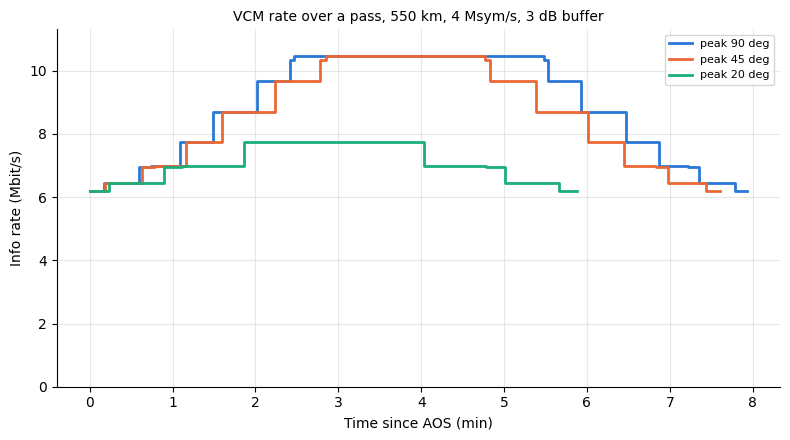

Overhead pass:  518.8 MB in 7.9 min
45 deg pass:    482.7 MB in 7.6 min
Average pass:   368.3 MB  ->  1.47 GB/day at 4 passes/day (PLACEHOLDER pass count)

PFD: worst case -4.3 dB vs the Table 21-4 limit (under); largest compliant PA output 5.43 W [benchmark only on the current licence route]


In [11]:
VCM_BUFFER = WAVEFORM["vcm_buffer_dB"]
grid, sched_modcod = vcm_schedule(VCM_BUFFER)
esn0_grid = link_budget(grid)["= Available Es/N0"]

sched = pd.DataFrame({"elev_deg": grid,
                      "modcod": MODCODS.modcod.to_numpy()[sched_modcod],
                      "info_rate_Mbps": RATE_BPS[sched_modcod]/1e6,
                      "predicted_margin_dB": esn0_grid - REQ_TOTAL_DB[sched_modcod]})   # NaN where off
steps = sched[sched["modcod"] != sched["modcod"].shift()]          # rows where the MODCOD changes
print(f"VCM schedule ({VCM_BUFFER:g} dB buffer, {WAVEFORM['Rs_sps']/1e6:g} Msym/s): each MODCOD is used from this elevation upward")
display(steps.set_index("elev_deg").round(2))

# ---- Chart: info rate over three example passes ----
fig, ax = plt.subplots(figsize=(8, 4.5))
for k, me in enumerate((90, 45, 20)):
    p = pass_profile(MISSION["alt_km"], MISSION["min_el_deg"], me, DT_S)
    idx, _ = modcod_at_elevation(grid, sched_modcod, p["el_deg"])
    ax.step(p["t"]/60, RATE_BPS[idx]/1e6, where="post", color=SERIES[k], label=f"peak {me} deg")
ax.set_ylim(0, RATE_BPS.max()/1e6*1.08)
ax.set_xlabel("Time since AOS (min)"); ax.set_ylabel("Info rate (Mbit/s)")
ax.set_title(f"VCM rate over a pass, {MISSION['alt_km']:g} km, {WAVEFORM['Rs_sps']/1e6:g} Msym/s, {VCM_BUFFER:g} dB buffer", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# ---- Data per pass (nominal: every frame decodes) ----
over_MB = deterministic_pass_MB(90, (grid, sched_modcod))
mid_MB  = deterministic_pass_MB(45, (grid, sched_modcod))
avg_MB  = average_pass_MB(VCM_BUFFER)
dur = {me: pass_profile(MISSION["alt_km"], MISSION["min_el_deg"], me)["T"] for me in (90, 45)}
print(f"Overhead pass: {over_MB:6.1f} MB in {dur[90]/60:.1f} min")
print(f"45 deg pass:   {mid_MB:6.1f} MB in {dur[45]/60:.1f} min")
print(f"Average pass:  {avg_MB:6.1f} MB  ->  {avg_MB*MISSION['passes_per_day']/1e3:.2f} GB/day "
      f"at {MISSION['passes_per_day']:g} passes/day (PLACEHOLDER pass count)")

# ---- PFD check ----
excess = pfd_worst_excess_dB()
print(f"\nPFD: worst case {excess:+.1f} dB vs the Table 21-4 limit "
      f"({'OVER' if excess > 0 else 'under'}); largest compliant PA output {pfd_max_power_W():.2f} W "
      f"[{'binding' if CONSTRAINTS['pfd_binding'] else 'benchmark only'} on the current licence route]")

## 6. Decision studies (deterministic)
Each study changes one or two `DECISIONS` choices and keeps everything else at baseline. All numbers are **average-pass MB, every frame decoding**, at the Section 2 buffer.

- **D1 × D2: pointing mode × antenna.** High-gain antennas have narrow beams: they only pay off if GNC steers them at the GS. With nadir pointing the GS sits up to ~65° off boresight at low elevation.
- **D3: PA power.** Each doubling adds 3 dB everywhere, so faster MODCODs at every elevation. Grey line: the 3 W structures limit. Hollow markers: designs over the PFD limit.

Average MB per pass, 2 W, 5 deg pointing error, 3 dB buffer


,steered,nadir
Near-omni (turnstile),286.8,192.5
Taoglas patch (baseline),368.3,145.7
Patch array 2x2,479.5,40.3
Helical (7-turn),485.1,20.5


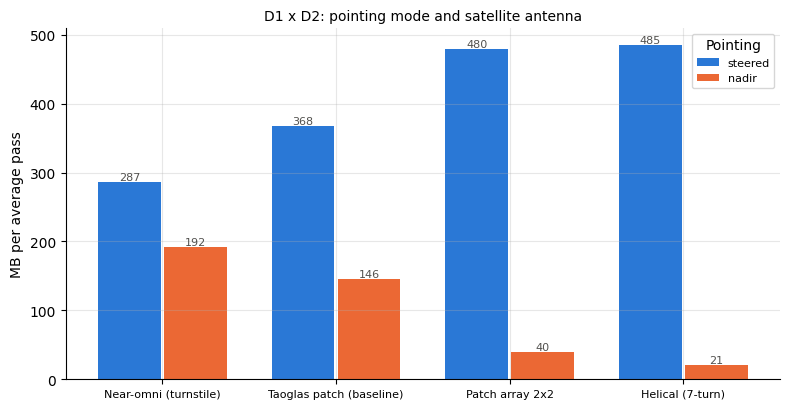

antenna,Helical (7-turn),Near-omni (turnstile),Patch array 2x2,Taoglas patch (baseline)
pa_W,,,,
1,468.9,198.4,436.5,286.2
2,485.1,286.8,479.5,368.3
3,485.1,337.6,485.1,409.9
5,485.1,392.1,485.1,457.7
7,485.1,427.1,485.1,476.7
10,485.1,457.7,485.1,485.1


PFD worst-case excess [dB] (> 0 = over the limit):


antenna,Helical (7-turn),Near-omni (turnstile),Patch array 2x2,Taoglas patch (baseline)
pa_W,,,,
1,0.4,-10.3,-1.5,-7.3
2,3.4,-7.3,1.5,-4.3
3,5.1,-5.5,3.3,-2.6
5,7.4,-3.3,5.5,-0.4
7,8.8,-1.9,7.0,1.1
10,10.4,-0.3,8.5,2.7


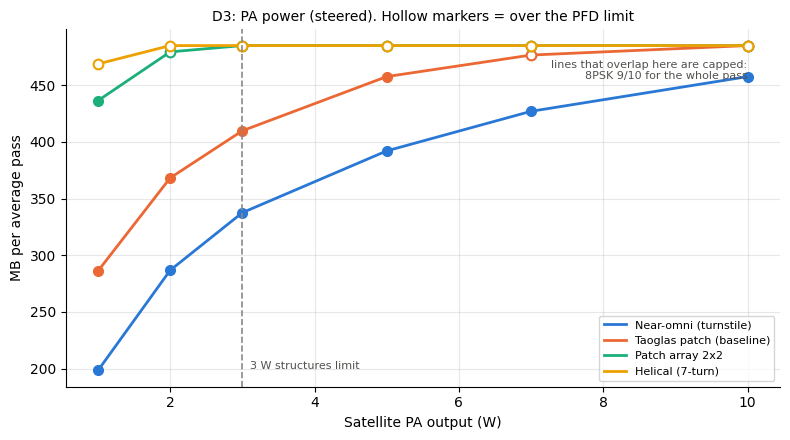

In [ ]:
# ---- D1 x D2: average MB per pass for each pointing mode and antenna, assuming VCM ----
d13 = pd.DataFrame({pt: [average_pass_MB(VCM_BUFFER, design=dict(ant=a, pointing=pt)) for a in CANDIDATES["ant"]]
                    for pt in CANDIDATES["pointing"]}, index=CANDIDATES["ant"])
print(f"Average MB per pass, {DECISIONS['pa_out_W']:g} W, {SAT_S['pointing_err_deg']:g} deg pointing error, {VCM_BUFFER:g} dB buffer")
display(d13.round(1))

fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(CANDIDATES["ant"])); w = 0.38
for k, pt in enumerate(CANDIDATES["pointing"]):
    bars = ax.bar(x + (k - 0.5)*w, d13[pt], w*0.95, color=SERIES[k], label=pt)
    ax.bar_label(bars, fmt="%.0f", fontsize=8, color="#52514e")
ax.set_xticks(x, CANDIDATES["ant"], fontsize=8)
ax.set_ylabel("MB per average pass"); ax.legend(title="Pointing", fontsize=8)
ax.set_title("D1 x D2: pointing mode and satellite antenna", fontsize=10)
plt.tight_layout(); plt.show()

# ---- D3: PA power for each antenna (steered), with the 3 W line and PFD flags ----
rows = []
for a in CANDIDATES["ant"]:
    for pw in CANDIDATES["pa_W"]:
        dsg = dict(ant=a, pa_out_W=pw, pointing="steered")
        rows.append(dict(antenna=a, pa_W=pw, avg_MB=average_pass_MB(VCM_BUFFER, design=dsg),
                         pfd_excess_dB=pfd_worst_excess_dB(dsg), over_struct=pw > CONSTRAINTS["pa_struct_W"]))
d4 = pd.DataFrame(rows)
display(d4.pivot(index="pa_W", columns="antenna", values="avg_MB").round(1))
print("PFD worst-case excess [dB] (> 0 = over the limit):")
display(d4.pivot(index="pa_W", columns="antenna", values="pfd_excess_dB").round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
for k, a in enumerate(CANDIDATES["ant"]):
    s = d4[d4.antenna == a]
    ax.plot(s.pa_W, s.avg_MB, color=SERIES[k], label=a)
    ok, bad = s[s.pfd_excess_dB <= 0], s[s.pfd_excess_dB > 0]
    ax.plot(ok.pa_W, ok.avg_MB, "o", ms=7, color=SERIES[k])
    ax.plot(bad.pa_W, bad.avg_MB, "o", ms=7, mfc="white", mec=SERIES[k], mew=1.5)
ax.axvline(CONSTRAINTS["pa_struct_W"], color=REF_GREY, ls="--", lw=1.2)
ax.text(CONSTRAINTS["pa_struct_W"] + 0.1, ax.get_ylim()[0] + 0.05*np.ptp(ax.get_ylim()), "3 W structures limit",
        fontsize=8, color="#52514e")
cap_MB = d4.avg_MB.max()
ax.text(CANDIDATES["pa_W"][-1], cap_MB - 0.04*np.ptp(ax.get_ylim()), f"lines that overlap here are capped:\n{MODCODS.modcod.iloc[-1]} for the whole pass",
        fontsize=8, color="#52514e", ha="right", va="top", transform=ax.transData)
ax.set_xlabel("Satellite PA output (W)"); ax.set_ylabel("MB per average pass")
ax.set_title("D3: PA power (steered). Hollow markers = over the PFD limit", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Monte Carlo: how much really gets through
Section 5 assumed every frame decodes. In reality the parts differ from their datasheets and the pointing wobbles. The schedule is still chosen from the **nominal** budget (it is uploaded before the pass), so a step fails when reality falls more than one buffer below the prediction.

**Two kinds of randomness**, kept separate on purpose:
- **Per-pass biases** (drawn once per simulated pass): satellite antenna gain, PA power, satellite cable loss, dish gain, system temperature (RFI that only ever adds noise, LNA noise figure), polarization mismatch, implementation loss. A part that is 1 dB low is 1 dB low for the whole pass, so failures come in stretches, not as random single frames.
- **Per-second jitter**: satellite pointing error (Rayleigh, with `SAT_S["pointing_err_deg"]` as its 95th percentile) and dish tracking loss.

Each simulated pass also gets a random ground-track offset, so the passes cover the realistic mix of high and low passes.

For every time sample: actual margin = predicted margin of the scheduled MODCOD + Δ, where Δ (dB) is the sum of all the deviations from nominal. The frame decodes if the actual margin ≥ 0.

**Outputs**
1. Distribution of delivered MB per pass at the Section 2 buffer.
2. Chance each schedule step decodes (vs elevation).
3. Tornado: how much delivered data each uncertainty costs (delivered MB with that one uncertainty removed, minus delivered MB with all of them). "Removed" means that term is held at its nominal value. A **negative** bar means the nominal value is pessimistic: the satellite pointing error is held at 5° (its 95th percentile) in the schedule, so the typical real error is smaller and removing the randomness makes things slightly worse.

Delivered data counts only frames that decode first time. Failed frames used airtime and are resent later, so they do not count towards this pass.

In [13]:
def draw_monte_carlo(n_passes=None, seed=RNG_SEED, design=None):
    '''Simulate n_passes passes. Returns one flat table of time samples (all passes concatenated) with:
    pass id, elevation, nominal available Es/N0, and each deviation component in dB (positive = better
    than nominal). Nothing here depends on the buffer, so Section 8 can reuse the same draws.'''
    n_passes = MC["n_passes"] if n_passes is None else n_passes
    d   = {**DECISIONS, **(design or {})}
    alt, mask = MISSION["alt_km"], MISSION["min_el_deg"]
    rng = np.random.default_rng(seed)

    # ---- per-pass biases [dB, positive = better link] ----
    bias = dict(
        sat_ant  = rng.normal(0, MC["sat_ant_std_dB"], n_passes),
        pa       = rng.normal(0, MC["pa_std_dB"], n_passes),
        sat_loss = -rng.normal(0, MC["sat_loss_std_dB"], n_passes),
        dish     = rng.normal(0, MC["dish_gain_std_dB"], n_passes),
        pol      = -(np.clip(rng.normal(GS_S["pol_loss_dB"], MC["pol_std_dB"], n_passes), 0, None) - GS_S["pol_loss_dB"]),
        impl     = -(np.clip(rng.normal(WAVEFORM["impl_loss_dB"], MC["impl_std_dB"], n_passes), 0, None) - WAVEFORM["impl_loss_dB"]),
    )
    T_ant = GS_S["T_ant_K"] + rng.exponential(MC["T_rfi_mean_K"], n_passes)          # RFI only adds noise
    nf    = np.clip(GS_S["lna_nf_dB"] + rng.normal(0, MC["lna_nf_std_dB"], n_passes), 0.1, None)
    tsys  = tsys_at_lna_input(T_ant, GS_S["feed_loss_dB"], nf, GS_S["lna_gain_dB"], GS_S["post_loss_dB"], GS_S["rx_nf_dB"])
    bias["tsys"] = -10*np.log10(tsys/TSYS_K)

    # ---- pass geometry: random ground-track offset per pass ----
    max_els = max_elevs(alt, mask, n_passes, rng)
    # Rayleigh scale so that P(error < pointing_err_deg) = 95%
    ray_sigma = SAT_S["pointing_err_deg"]/np.sqrt(-2*np.log(0.05))

    parts = []
    for i, me in enumerate(max_els):
        p = pass_profile(alt, mask, me, DT_S)
        el = p["el_deg"]; n = len(el)
        if n == 0:
            continue
        nominal = link_budget(el, design=d)            # nominal budget uses the 5 deg error, like the schedule
        err = rng.rayleigh(ray_sigma, n)                 # actual satellite pointing error each second
        sat_pt = nominal["- Sat pointing loss"] - sat_point_loss_db(alt, el, d["ant"], err, d["pointing"])
        dish_pt = GS_S["point_loss_dB"] - np.clip(GS_S["point_loss_dB"] + rng.normal(0, MC["dish_point_std_dB"], n), 0, None)
        row = dict(pass_id=np.full(n, i), el_deg=el, esn0_nom=nominal["= Available Es/N0"],
                   sat_point=sat_pt, dish_point=dish_pt)
        for k, v in bias.items():
            row[k] = np.full(n, v[i])
        parts.append(pd.DataFrame(row))
    samples = pd.concat(parts, ignore_index=True)
    samples.attrs.update(n_passes=n_passes, components=list(bias) + ["sat_point", "dish_point"])
    return samples

def evaluate_buffer(samples, buffer_dB, drop=()):
    '''Apply one buffer to the Monte Carlo samples.
    drop: uncertainty components to switch off (for the tornado).
    Returns dict: mean delivered and transmitted MB per pass, overall reliability (delivered / transmitted
    bits), worst-step reliability (lowest decode rate of any schedule step), per-step decode table,
    and delivered MB per pass.'''
    grid, sched_modcod = vcm_schedule(buffer_dB)
    idx, step = modcod_at_elevation(grid, sched_modcod, samples["el_deg"].to_numpy())
    on = idx > 0                                    # row 0 = transmitter off
    rate = RATE_BPS[idx]                            # 0 when off
    delta = sum(samples[c].to_numpy() for c in samples.attrs["components"] if c not in drop)
    decoded = (samples["esn0_nom"].to_numpy() - REQ_TOTAL_DB[idx] + delta) >= 0   # NaN ("off") -> False

    scale = DT_S*WAVEFORM["payload_frac"]/8e6       # bits/s * s -> MB
    n_passes = samples.attrs["n_passes"]
    sent_MB = rate.sum()*scale/n_passes
    good_MB = (rate*decoded).sum()*scale/n_passes
    per_pass = pd.Series(rate*decoded*scale).groupby(samples["pass_id"].to_numpy()).sum()

    st = pd.DataFrame(dict(step=step[on], el=grid[step[on]], decoded=decoded[on]))
    per_step = st.groupby("el").decoded.agg(["mean", "size"])
    per_step = per_step[per_step["size"] >= 30]                 # ignore steps with too few samples to trust
    return dict(good_MB=good_MB, sent_MB=sent_MB,
                overall_rel=good_MB/sent_MB if sent_MB > 0 else np.nan,
                worst_rel=per_step["mean"].min() if len(per_step) else np.nan,
                per_step=per_step, per_pass=per_pass)

SAMPLES = draw_monte_carlo()
print(f"Monte Carlo: {SAMPLES.attrs['n_passes']} passes, {len(SAMPLES):,} one-second samples")

Monte Carlo: 600 passes, 223,771 one-second samples


Buffer 3 dB: mean delivered 334.7 MB/pass of 363.8 MB sent (nominal average pass: 368.3 MB)
Overall reliability 92.0%  ->  8.0% of transmitted data needs a resend
Worst schedule step decodes 85.6% of the time
Delivered per pass: median 365.6 MB, 10th percentile 106.3 MB, 90th percentile 512.8 MB


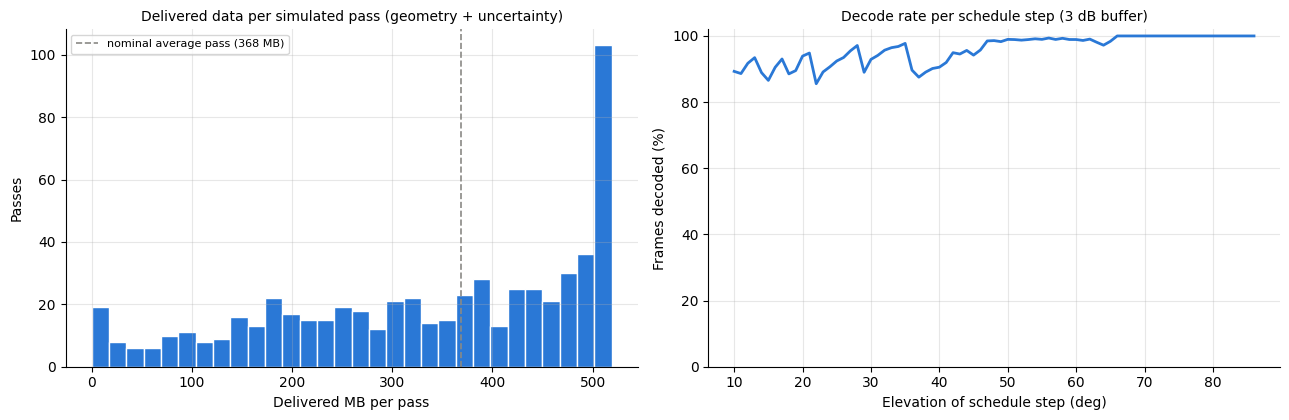

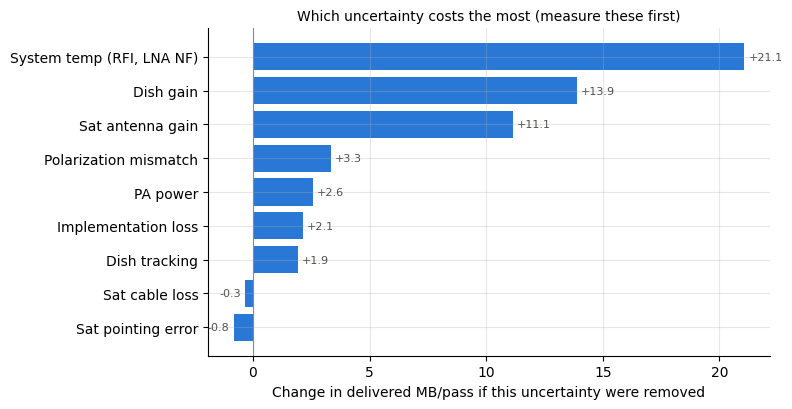

In [14]:
res = evaluate_buffer(SAMPLES, VCM_BUFFER)
print(f"Buffer {VCM_BUFFER:g} dB: mean delivered {res['good_MB']:.1f} MB/pass of {res['sent_MB']:.1f} MB sent "
      f"(nominal average pass: {avg_MB:.1f} MB)")
print(f"Overall reliability {res['overall_rel']:.1%}  ->  {1 - res['overall_rel']:.1%} of transmitted data needs a resend")
print(f"Worst schedule step decodes {res['worst_rel']:.1%} of the time")
pp = res["per_pass"]
print(f"Delivered per pass: median {pp.median():.1f} MB, 10th percentile {pp.quantile(0.1):.1f} MB, "
      f"90th percentile {pp.quantile(0.9):.1f} MB")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].hist(pp, bins=30, color=SERIES[0], edgecolor="white")
axes[0].axvline(avg_MB, color=REF_GREY, ls="--", lw=1.2, label=f"nominal average pass ({avg_MB:.0f} MB)")
axes[0].set_xlabel("Delivered MB per pass"); axes[0].set_ylabel("Passes")
axes[0].set_title("Delivered data per simulated pass (geometry + uncertainty)", fontsize=10)
axes[0].legend(fontsize=8)

ps = res["per_step"]
axes[1].plot(ps.index, 100*ps["mean"], color=SERIES[0])
axes[1].set_ylim(0, 102)
axes[1].set_xlabel("Elevation of schedule step (deg)"); axes[1].set_ylabel("Frames decoded (%)")
axes[1].set_title(f"Decode rate per schedule step ({VCM_BUFFER:g} dB buffer)", fontsize=10)
plt.tight_layout(); plt.show()

# ---- Tornado: delivered MB gained if each uncertainty were removed ----
labels = dict(sat_ant="Sat antenna gain", pa="PA power", sat_loss="Sat cable loss", dish="Dish gain",
              pol="Polarization mismatch", impl="Implementation loss", tsys="System temp (RFI, LNA NF)",
              sat_point="Sat pointing error", dish_point="Dish tracking")
gain = pd.Series({labels[c]: evaluate_buffer(SAMPLES, VCM_BUFFER, drop=(c,))["good_MB"] - res["good_MB"]
                  for c in SAMPLES.attrs["components"]}).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.barh(gain.index, gain.values, color=SERIES[0])
ax.bar_label(bars, fmt="%+.1f", fontsize=8, color="#52514e", padding=3)
ax.axvline(0, color=REF_GREY, lw=0.8)
ax.set_xlabel("Change in delivered MB/pass if this uncertainty were removed")
ax.set_title("Which uncertainty costs the most (measure these first)", fontsize=10)
plt.tight_layout(); plt.show()

## 8. Choosing the VCM buffer (D4)
The buffer trades speed for reliability. A small buffer picks fast MODCODs that often fail; a large buffer picks slow MODCODs that almost always decode. We sweep it, reusing the **same** Monte Carlo draws for every value (so the curves are smooth and comparable), and look at:

- **Delivered MB per pass** (first-time decodes only). This is what we maximise.
- **Overall reliability** = delivered ÷ transmitted data. `1 − overall` is the share of transmitted data that must be resent on a later pass.
- **Worst-step reliability** = the decode rate of the weakest schedule step. Because errors are mostly per-pass biases, a low worst step means some passes systematically fail at those elevations, which costs UHF uplink capacity for resend requests, delay and onboard backlog. We require it to stay above `BUFFER_SWEEP["worst_step_floor"]`.

**Recommendation rule:** the buffer that maximises delivered MB per pass among buffers whose worst step meets the floor. Copy it into `WAVEFORM["vcm_buffer_dB"]` and re-run.

,good_MB,sent_MB,overall_rel_pct,worst_rel_pct
buffer_dB,,,,
0.0,257.2,432.8,59.4,35.5
0.5,275.8,425.2,64.8,43.8
1.0,297.1,412.2,72.1,56.1
1.5,311.2,401.4,77.5,63.9
2.0,324.9,387.7,83.8,72.6
2.5,331.6,377.3,87.9,80.0
3.0,334.7,363.8,92.0,85.6
3.5,334.2,353.3,94.6,89.5
4.0,327.3,337.5,97.0,94.2


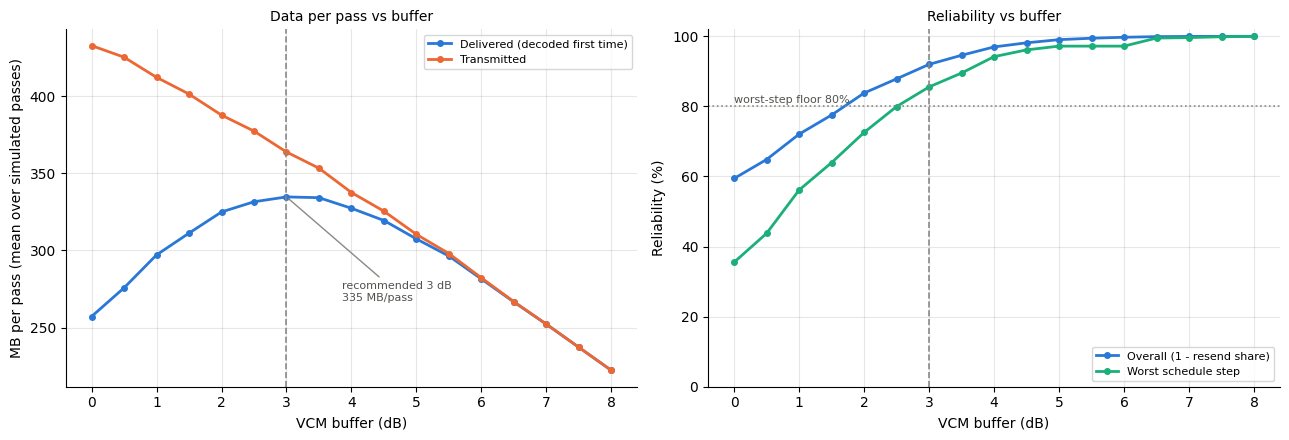

Unconstrained maximum: 334.7 MB/pass at 3 dB (worst step 86%)
Recommended buffer (worst step >= 80%): 3 dB -> 334.7 MB/pass, overall reliability 92.0% (resend 8.0%), worst step 85.6%
-> set WAVEFORM['vcm_buffer_dB'] = 3 in Section 2 and re-run


In [ ]:
# ---- The sweep: try every candidate VCM buffer against the SAME 600 simulated passes ----
# What is swept: only the buffer (0, 0.5, ..., 8 dB from BUFFER_SWEEP["buffers_dB"]). For each value,
# evaluate_buffer builds a new VCM schedule with that buffer (bigger buffer -> slower, safer MODCODs),
# flies it through the Section 7 samples, and counts what decodes.
sweep = pd.DataFrame([dict(buffer_dB=bf, **{k: v for k, v in evaluate_buffer(SAMPLES, bf).items()
                                            if k in ("good_MB", "sent_MB", "overall_rel", "worst_rel")})
                      for bf in BUFFER_SWEEP["buffers_dB"]])

# ---- Pick the recommended buffer ----
# Rule: among buffers whose weakest step still decodes on >= floor (80%) of passes, take the one that
# delivers the most data.
floor = BUFFER_SWEEP["worst_step_floor"]
feasible = sweep[sweep.worst_rel >= floor]                       # buffers that pass the reliability floor
best_any = sweep.loc[sweep.good_MB.idxmax()]                     # most data ignoring the floor (for comparison)
BUFFER_REC = float(feasible.loc[feasible.good_MB.idxmax(), "buffer_dB"]) if len(feasible) else float("nan")
rec = sweep[sweep.buffer_dB == BUFFER_REC].iloc[0] if len(feasible) else None   # the full row for the pick

display(sweep.assign(overall_rel_pct=100*sweep.overall_rel, worst_rel_pct=100*sweep.worst_rel)
             [["buffer_dB", "good_MB", "sent_MB", "overall_rel_pct", "worst_rel_pct"]].round(1).set_index("buffer_dB"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
# Left: delivered (and transmitted) data per pass vs buffer
ax1.plot(sweep.buffer_dB, sweep.good_MB, color=SERIES[0], marker="o", ms=4, label="Delivered (decoded first time)")
ax1.plot(sweep.buffer_dB, sweep.sent_MB, color=SERIES[1], marker="o", ms=4, label="Transmitted")
if rec is not None:
    ax1.axvline(BUFFER_REC, color=REF_GREY, ls="--", lw=1.2)
    ax1.annotate(f"recommended {BUFFER_REC:g} dB\n{rec.good_MB:.0f} MB/pass", (BUFFER_REC, rec.good_MB),
                 xytext=(40, -75), textcoords="offset points", fontsize=8, color="#52514e",
                 arrowprops=dict(arrowstyle="-", color=REF_GREY))
ax1.set_xlabel("VCM buffer (dB)"); ax1.set_ylabel("MB per pass (mean over simulated passes)")
ax1.set_title("Data per pass vs buffer", fontsize=10); ax1.legend(fontsize=8)
# Right: overall and worst-step reliability vs buffer
ax2.plot(sweep.buffer_dB, 100*sweep.overall_rel, color=SERIES[0], marker="o", ms=4, label="Overall (1 - resend share)")
ax2.plot(sweep.buffer_dB, 100*sweep.worst_rel, color=SERIES[2], marker="o", ms=4, label="Worst schedule step")
ax2.axhline(100*floor, color=REF_GREY, ls=":", lw=1.2)
ax2.text(sweep.buffer_dB.min(), 100*floor + 1, f"worst-step floor {floor:.0%}", fontsize=8, color="#52514e")
if rec is not None:
    ax2.axvline(BUFFER_REC, color=REF_GREY, ls="--", lw=1.2)
ax2.set_ylim(0, 102)
ax2.set_xlabel("VCM buffer (dB)"); ax2.set_ylabel("Reliability (%)")
ax2.set_title("Reliability vs buffer", fontsize=10); ax2.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

print(f"Unconstrained maximum: {best_any.good_MB:.1f} MB/pass at {best_any.buffer_dB:g} dB "
      f"(worst step {best_any.worst_rel:.0%})")
if rec is not None:
    print(f"Recommended buffer (worst step >= {floor:.0%}): {BUFFER_REC:g} dB -> {rec.good_MB:.1f} MB/pass, "
          f"overall reliability {rec.overall_rel:.1%} (resend {1 - rec.overall_rel:.1%}), worst step {rec.worst_rel:.1%}")
    print(f"-> set WAVEFORM['vcm_buffer_dB'] = {BUFFER_REC:g} in Section 2 and re-run")
else:
    print(f"No buffer in the sweep meets the {floor:.0%} worst-step floor: widen the sweep or revisit the floor")

## 9. Summary for the systems meeting
One table for the baseline design at the **recommended** buffer from Section 8 (not necessarily the Section 2 value). Per-day numbers use the placeholder pass count, so treat them as relative until a TLE pass count replaces it.

In [16]:
b_use = BUFFER_REC if np.isfinite(BUFFER_REC) else VCM_BUFFER
mc = evaluate_buffer(SAMPLES, b_use)
summary = pd.Series({
    "Altitude":                     f"{MISSION['alt_km']:g} km circular",
    "Elevation mask":               f"{MISSION['min_el_deg']:g} deg",
    "D1 pointing mode":             DECISIONS["pointing"],
    "D2 satellite antenna":         DECISIONS["ant"],
    "D3 PA output":                 f"{DECISIONS['pa_out_W']:g} W ({'over' if DECISIONS['pa_out_W'] > CONSTRAINTS['pa_struct_W'] else 'within'} the {CONSTRAINTS['pa_struct_W']:g} W structures limit)",
    "Symbol rate / bandwidth":      f"{WAVEFORM['Rs_sps']/1e6:g} Msym/s / ~{WAVEFORM['Rs_sps']*(1 + WAVEFORM['rolloff'])/1e6:.1f} MHz",
    "D4 VCM buffer (recommended)":  f"{b_use:g} dB",
    "Nominal MB per average pass":  f"{average_pass_MB(b_use):.1f}",
    "MC delivered MB per pass":     f"{mc['good_MB']:.1f} mean, {mc['per_pass'].quantile(0.1):.1f} at 10th percentile",
    "Overall reliability / resend": f"{mc['overall_rel']:.1%} / {1 - mc['overall_rel']:.1%}",
    "Worst-step reliability":       f"{mc['worst_rel']:.1%}",
    "MB per day (placeholder)":     f"{mc['good_MB']*MISSION['passes_per_day']:.0f} at {MISSION['passes_per_day']:g} passes/day",
    "PFD worst-case excess":        f"{pfd_worst_excess_dB():+.1f} dB ({'binding' if CONSTRAINTS['pfd_binding'] else 'benchmark'}); max compliant PA {pfd_max_power_W():.2f} W",
}, name="value")
display(summary.to_frame())

,value
Altitude,550 km circular
Elevation mask,10 deg
D1 pointing mode,steered
D2 satellite antenna,Taoglas patch (baseline)
D3 PA output,2 W (within the 3 W structures limit)
Symbol rate / bandwidth,4 Msym/s / ~4.8 MHz
D4 VCM buffer (recommended),3 dB
Nominal MB per average pass,368.3
MC delivered MB per pass,"334.7 mean, 106.3 at 10th percentile"
Overall reliability / resend,92.0% / 8.0%


**Open items that move these numbers most** (see the Section 7 tornado for the ranking)
- Measure the roof noise floor (RFI / Wi-Fi) and the real GS antenna temperature.
- Confirm the satellite antenna's gain, beamwidth and polarization; confirm the GNC pointing performance.
- Replace `passes_per_day` and the uniform-track assumption with TLE-propagated passes once the inclination is known.
- Settle the licence route (sets whether the PFD limit binds) and the IARU frequency.
- Re-tune the buffer from measured signal levels on the first passes.